In [1]:
import os
# Evita que numpy/BLAS use varios hilos por proceso (si no, se pisan con el pool)
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_v] = "1"
 
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import emcee
import phoebe
from phoebe import u
 
# =====================================================================
# CONFIGURACIÓN
# =====================================================================
MODE = "fase1"             # "fase1" o "fase2"; el argumento de terminal tiene prioridad
if len(sys.argv) > 1 and sys.argv[1] in ("fase1", "fase2"):
    MODE = sys.argv[1]
 
FILE_R = "C:/Users/darkm/Desktop/archivos_Investigación/PHOEBE}/TYC_6265_2079_flujo_r.txt"
FILE_I = "C:/Users/darkm/Desktop/archivos_Investigación/PHOEBE}/TYC_6265_2079_flujo_i.txt"
 
BUNDLE_OUT = "TYC6265_emcee.bundle"     # compartido por las dos fases (misma carpeta)
USE_EBAI   = True
USE_NM     = True                       # Nelder-Mead antes de emcee
DISTORTION = "sphere"                   # 'sphere' (rápido) o 'roche'. Con 'sphere' q NO influye
 
# --- fase 1 ---
PHASES_MESH = [0.0, 0.25, 0.5, 0.75]    # fases en las que se dibuja la morfología
 
# --- fase 2 ---
NPROCS    = max(1, (os.cpu_count() or 2) // 2 - 1)   # núcleos físicos - 1 (ajusta a mano)
NWALKERS  = 2 * NPROCS * 2                            # >= 2*nparams y múltiplo de 2*NPROCS
CHUNK     = 250                                       # iteraciones por bloque
N_CHUNKS  = 10                                        # máx. bloques (total = CHUNK*N_CHUNKS)
RESUME    = True                                      # si el bundle existe, continúa desde ahí
 
# Parámetros libres y sus priors (ajusta los rangos a tu criterio físico)
# q queda FIJO: con solo fotometría y 'sphere' no tiene efecto.
PRIORS = {
    "t0_supconj@binary":    lambda t0: phoebe.gaussian(t0, 0.02),
    "period@binary":        lambda P:  phoebe.uniform(P - 0.002, P + 0.002),
    "incl@binary":          lambda i:  phoebe.uniform(60.0, 90.0),
    "teff@primary":         lambda T:  phoebe.gaussian(25700.0, 1000.0),
    "teffratio@binary":     lambda r:  phoebe.uniform(0.5, 1.1),
    "requivsumfrac@binary": lambda s:  phoebe.uniform(0.05, 0.60),
    "requivratio@binary":   lambda r:  phoebe.uniform(0.2, 2.0),
}
# Dispersión de la bolita inicial de walkers (alrededor de la solución del optimizador)
INIT_SIGMA = {
    "t0_supconj@binary": 2e-3, "period@binary": 2e-5, "incl@binary": 0.5,
    "teff@primary": 100.0, "teffratio@binary": 0.01,
    "requivsumfrac@binary": 0.005, "requivratio@binary": 0.02,
}
 
 
# =====================================================================
# COMÚN: bundle, optimizador, distribuciones
# =====================================================================
def load(path):
    d = np.genfromtxt(path, delimiter=None, skip_header=1, encoding="latin1")
    return d[:, 0], d[:, 1], d[:, 2]
 
 
def build_bundle():
    t_r, f_r, e_r = load(FILE_R)
    t_i, f_i, e_i = load(FILE_I)
 
    b = phoebe.default_binary()
    b.add_dataset("lc", times=t_r, fluxes=f_r, sigmas=e_r, passband="SDSS:r", dataset="lc01")
    b.add_dataset("lc", times=t_i, fluxes=f_i, sigmas=e_i, passband="SDSS:i", dataset="lc02")
 
    b["period@binary"] = 3.6788 * u.day
    b["t0_supconj@binary"] = t_r[0] * u.day
    b["incl@binary"] = 70.0 * u.deg
    b["q@binary"] = 0.5
    b["teff@primary"] = 25700 * u.K
    b["teff@secondary"] = 20000 * u.K
    b["ecc@binary"] = 0.0
 
    b.set_value_all("atm", "ck2004")
    b.set_value_all("ld_mode", "interp")
    b.set_value_all("ld_mode_bol", "manual")
    b.set_value_all("gravb_bol", 1.0)            # estrellas radiativas
    b.set_value_all("irrad_frac_refl_bol", 1.0)
    b.set_value_all("pblum_mode", "dataset-scaled")
    b.set_value_all("irrad_method", "horvat")
 
    # Constraints: orden que te funcionó: requivsumfrac -> requivratio -> teffratio.
    # (Si PHOEBE se queja del solve_for, usa tu bloque que ya funcionaba.)
    b.flip_constraint("requivsumfrac", solve_for="requiv@secondary")
    b.flip_constraint("requivratio", solve_for="requiv@primary")
    b.flip_constraint("teffratio", solve_for="teff@secondary")
 
    b["requivsumfrac@binary"] = 0.30
    b["requivratio@binary"] = 0.60
 
    b.add_compute("phoebe", compute="optim_compute", irrad_method="none",
                  distortion_method=DISTORTION)
    b.add_compute("phoebe", compute="final_compute", irrad_method="horvat",
                  distortion_method="roche")
    return b
 
 
def check_free(b):
    """Todos los parámetros muestreados deben ser independientes (no constraints)."""
    for twig in PRIORS:
        p = b.get_parameter(twig, context="component")
        assert p.is_constraint is None, f"{twig} sigue siendo un constraint; revisa los flip_constraint"
 
 
def optimize(b):
    if USE_EBAI:
        b.add_solver("estimator.ebai", ebai_method="knn", solver="ebai_knn")
        b.run_solver("ebai_knn", solution="ebai_knn_solution")
        b.adopt_solution("ebai_knn_solution",
                         adopt_parameters=["t0_supconj", "incl", "teffratio", "requivsumfrac"],
                         adopt_values=True)
    if USE_NM:
        b.add_solver("optimizer.nelder_mead", solver="opt_nm", compute="optim_compute",
                     fit_parameters=list(PRIORS.keys()), maxiter=400)
        b.run_solver("opt_nm", solution="opt_nm_sol", lc_datasets=["lc01", "lc02"])
        print(b.adopt_solution("opt_nm_sol", trial_run=True))
        b.adopt_solution("opt_nm_sol")
 
 
def add_distributions(b):
    priors = {tw: f(b.get_value(tw, context="component")) for tw, f in PRIORS.items()}
    b.add_distribution(priors, distribution="dist_prior")
    init = {tw: phoebe.gaussian_around(INIT_SIGMA[tw]) for tw in PRIORS}
    b.add_distribution(init, distribution="dist_init")
 
 
def add_emcee_solver(b):
    b.add_solver("sampler.emcee", solver="emcee_solver", compute="optim_compute",
                 init_from="dist_init", priors="dist_prior", nwalkers=NWALKERS, niters=CHUNK)
 
 
# =====================================================================
# FASE 1: verificar el modelo en el óptimo (ajuste, residuos, eclipses, mesh)
# =====================================================================
def get_bundle(b_mem=None):
    """Prioridad: 'b' en memoria > bundle guardado > construir y optimizar desde cero (lento)."""
    if b_mem is not None:
        print("Usando 'b' en memoria")
        return b_mem
    if os.path.exists(BUNDLE_OUT):
        print(f"Cargando {BUNDLE_OUT}")
        return phoebe.load(BUNDLE_OUT)
    print("No hay bundle guardado: construyendo y optimizando (lento, ~40 min)")
    b = build_bundle()
    check_free(b)
    optimize(b)
    add_distributions(b)
    return b
 
 
def eclipse_depths(phase, flux):
    ph = ((phase + 0.5) % 1.0) - 0.5                       # [-0.5, 0.5)
    def level(mask):
        return np.median(flux[mask]) if mask.sum() > 3 else np.nan
    quad = level(np.abs(np.abs(ph) - 0.25) < 0.05)         # nivel fuera de eclipse
    prim = level(np.abs(ph) < 0.02)
    sec = level(np.abs(np.abs(ph) - 0.5) < 0.02)
    return 1 - prim / quad, 1 - sec / quad
 
 
def _ensure_inline_backend():
    """En Jupyter, fuerza gráficos en línea (un matplotlib.use('Agg') previo en el kernel los apaga)."""
    if "ipykernel" in sys.modules:
        try:
            from IPython import get_ipython
            get_ipython().run_line_magic("matplotlib", "inline")
        except Exception as e:
            print(f"No pude activar %matplotlib inline ({e}); ejecútalo tú en una celda.")
 
 
def fase1_verificar(b):
    _ensure_inline_backend()
    # --- 0. protección del óptimo ---
    if "bench" in b.models:                  # resto de un benchmark interrumpido
        b.remove_model("bench")
    b.save(BUNDLE_OUT)
    print("Óptimo guardado en:", os.path.abspath(BUNDLE_OUT))
 
    # --- 1. parámetros ajustados y cantidades derivadas ---
    # context="component": las distribuciones (dist_prior/dist_init) crean twigs duplicados
    def val(twig):
        return b.get_value(twig, context="component")
    P, t0 = val("period@binary"), val("t0_supconj@binary")
    incl, q = val("incl@binary"), val("q@binary")
    sma = val("sma@binary@component")
    R1, R2 = val("requiv@primary@component"), val("requiv@secondary@component")
    RL1, RL2 = val("requiv_max@primary@component"), val("requiv_max@secondary@component")
    T1, T2 = val("teff@primary@component"), val("teff@secondary@component")
 
    print(f"\nPeriodo            : {P:.6f} d")
    print(f"t0_supconj         : {t0:.5f}")
    print(f"Inclinación        : {incl:.2f} deg")
    print(f"q (fijo)           : {q:.3f}")
    print(f"Teff1 / Teff2      : {T1:.0f} K / {T2:.0f} K   (razón = {T2/T1:.4f})")
    print(f"(R1+R2)/a          : {(R1+R2)/sma:.4f}")
    print(f"R2/R1              : {R2/R1:.4f}")
    print(f"R1/a , R2/a        : {R1/sma:.4f} , {R2/sma:.4f}")
    print(f"Llenado del lóbulo : R1/RL1 = {R1/RL1:.3f} , R2/RL2 = {R2/RL2:.3f}   (1.0 = contacto)")
    print("Nota: solo con fotometría, 'sma' y los radios absolutos son degenerados; usa las fracciones.")
 
    # --- 2. modelos: optim_compute (el de emcee) y final_compute (roche + horvat) ---
    for comp, tag in [("optim_compute", "check_opt"), ("final_compute", "check_final")]:
        t_ = time.time()
        b.run_compute(compute=comp, model=tag, overwrite=True)
        print(f"{comp}: {time.time() - t_:.1f} s por modelo")
 
    for tag in ["check_opt", "check_final"]:
        print(f"\n=== {tag} ===")
        b.plot(dataset=["lc01", "lc02"], model=tag, x="phases", show=True, legend=True,
               save=f"{tag}_ajuste.png")
        b.plot(model=tag, kind="lc", x="phases", y="residuals", show=True, legend=True, marker="o",
               save=f"{tag}_residuos.png")
        for ds in ["lc01", "lc02"]:
            n = len(b.get_value("times", dataset=ds, context="dataset"))
            try:
                chi2 = b.calculate_chi2(model=tag, dataset=ds)
                print(f"{ds}: chi2 = {chi2:.1f}   chi2_red = {chi2 / n:.2f}   (N = {n})")
            except Exception as e:
                print(f"{ds}: calculate_chi2 no disponible en esta versión ({e})")
 
    # --- 3. ¿eclipse primario en fase 0? (detecta intercambio primaria/secundaria) ---
    print(f"\nteffratio = {T2 / T1:.3f}  ->  con razón < 1 el mínimo de fase 0 debe ser MÁS profundo que el de 0.5")
    for ds in ["lc01", "lc02"]:
        t_obs = np.array(b.get_value("times", dataset=ds, context="dataset"))
        f_obs = np.array(b.get_value("fluxes", dataset=ds, context="dataset"))
        t_mod = np.array(b.get_value("times", model="check_opt", dataset=ds, context="model"))
        f_mod = np.array(b.get_value("fluxes", model="check_opt", dataset=ds, context="model"))
        d_obs = eclipse_depths((t_obs - t0) / P, f_obs)
        d_mod = eclipse_depths((t_mod - t0) / P, f_mod)
        print(f"{ds}: profundidad fase 0 / fase 0.5 -> datos {d_obs[0]:.3f} / {d_obs[1]:.3f}"
              f"  |  modelo {d_mod[0]:.3f} / {d_mod[1]:.3f}")
 
    # --- 4. morfología (mesh) en una COPIA, para no tocar el bundle de emcee ---
    bm = b.copy()
    for ds in ["lc01", "lc02"]:
        try:
            bm.disable_dataset(ds)
        except Exception:
            pass
 
    times_mesh = [t0 + ph * P for ph in PHASES_MESH]
    try:
        bm.add_dataset("mesh", compute_times=times_mesh, dataset="mesh01", columns=["teffs", "loggs"])
    except Exception:
        bm.add_dataset("mesh", times=times_mesh, dataset="mesh01", columns=["teffs", "loggs"])
    bm.run_compute(compute="final_compute", model="mesh_model", overwrite=True)
 
    for ph, t in zip(PHASES_MESH, times_mesh):
        print(f"Plano del cielo, fase {ph}")
        bm.plot(model="mesh_model", dataset="mesh01", time=t, fc="teffs", ec="face", show=True,
                save=f"mesh_cielo_fase{ph}.png")
 
    for ph, t in zip(PHASES_MESH, times_mesh):
        print(f"Plano orbital (desde arriba), fase {ph}")
        try:
            bm.plot(model="mesh_model", dataset="mesh01", time=t, x="xs", y="ys",
                    fc="loggs", ec="face", show=True, save=f"mesh_orbital_fase{ph}.png")
        except Exception as e:
            print(f"  vista orbital no disponible ({e})")
            break
    return b
 
 
# =====================================================================
# FASE 2: emcee (paralelización + convergencia)
# =====================================================================
def setup_parallel():
    phoebe.multiprocessing_set_nprocs(NPROCS)
    phoebe.multiprocessing_on()
    print(f"[paralelo] multiprocessing ON con {NPROCS} procesos, {NWALKERS} walkers")
    # Alternativa MPI (Linux/WSL):  mpirun -np N python este_script.py fase2
 
 
def benchmark(b):
    t = time.time()
    b.run_compute(compute="optim_compute", model="bench", overwrite=True)
    dt = time.time() - t
    total_h = dt * NWALKERS * CHUNK * N_CHUNKS / NPROCS / 3600
    print(f"[bench] 1 modelo = {dt:.2f} s  ->  estimado máx. ~{total_h:.1f} h para {CHUNK*N_CHUNKS} iteraciones")
    b.remove_model("bench")
    return dt
 
 
def get_arrays(b, sol):
    chain = np.array(b.get_value("samples", solution=sol))          # (niters, nwalkers, nparams)
    lnp = np.array(b.get_value("lnprobabilities", solution=sol))     # (niters, nwalkers)
    if chain.shape[1] != NWALKERS and chain.shape[0] == NWALKERS:
        chain = np.swapaxes(chain, 0, 1)
        lnp = lnp.T
    return chain, lnp
 
 
def rhat(chain):
    """Gelman-Rubin sobre la segunda mitad de la cadena (walkers = cadenas)."""
    c = chain[chain.shape[0] // 2:]
    n = c.shape[0]
    W = c.var(axis=0, ddof=1).mean(axis=0)
    B = n * c.mean(axis=0).var(axis=0, ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)
 
 
def diagnostics(chain, twigs, tag="", plot=True):
    n = chain.shape[0]
    tau = emcee.autocorr.integrated_time(chain, tol=0, quiet=True)
    R = rhat(chain)
    print(f"\n--- Convergencia ({tag}) | {n} iteraciones x {chain.shape[1]} walkers ---")
    print(f"{'parámetro':28s} {'tau':>8s} {'N/tau':>8s} {'R-hat':>7s}")
    for k, tw in enumerate(twigs):
        print(f"{tw:28s} {tau[k]:8.1f} {n/tau[k]:8.1f} {R[k]:7.3f}")
    converged = bool(np.all(n > 50 * tau) and np.all(R < 1.05))
    print("=> CONVERGIÓ (N>50*tau y R-hat<1.05)" if converged else "=> aún NO converge")
 
    if plot:
        Ns = np.unique(np.exp(np.linspace(np.log(min(100, n)), np.log(n), 10)).astype(int))
        tau_n = np.array([emcee.autocorr.integrated_time(chain[:N], tol=0, quiet=True) for N in Ns])
        fig, ax = plt.subplots(figsize=(6, 4))
        for k, tw in enumerate(twigs):
            ax.loglog(Ns, tau_n[:, k], "o-", label=tw.split("@")[0])
        ax.plot(Ns, Ns / 50.0, "k--", label="N/50")
        ax.set_xlabel("iteraciones N"); ax.set_ylabel("tau estimado"); ax.legend(fontsize=7)
        fig.tight_layout(); fig.savefig(f"conv_tau_{tag}.png", dpi=150); plt.close(fig)
    return tau, R, converged
 
 
def trace_plots(chain, lnp, twigs, burnin, tag=""):
    d = chain.shape[2]
    fig, axes = plt.subplots(d + 1, 1, figsize=(8, 1.7 * (d + 1)), sharex=True)
    for k in range(d):
        axes[k].plot(chain[:, :, k], alpha=0.25, lw=0.6)
        axes[k].axvline(burnin, color="r", ls="--")
        axes[k].set_ylabel(twigs[k].split("@")[0], fontsize=7)
    axes[-1].plot(lnp, alpha=0.25, lw=0.6)
    axes[-1].axvline(burnin, color="r", ls="--"); axes[-1].set_ylabel("lnprob"); axes[-1].set_xlabel("iteración")
    fig.tight_layout(); fig.savefig(f"trazas_{tag}.png", dpi=150); plt.close(fig)
 
 
def corner_plot(chain, twigs, burnin, thin, tag=""):
    try:
        import corner
    except ImportError:
        print("pip install corner  para el corner plot"); return
    flat = chain[burnin::thin].reshape(-1, chain.shape[2])
    fig = corner.corner(flat, labels=[t.split("@")[0] for t in twigs], quantiles=[0.16, 0.5, 0.84],
                        show_titles=True, title_fmt=".4f")
    fig.savefig(f"corner_{tag}.png", dpi=150); plt.close(fig)
 
 
def fase2_emcee():
    plt.switch_backend("Agg")                # guarda figuras a archivo
    chain = lnp = prev = last_sol = None
    start = 0
 
    if RESUME and os.path.exists(BUNDLE_OUT):
        # Retoma: carga el bundle guardado y reconstruye la cadena de los bloques ya corridos
        b = phoebe.load(BUNDLE_OUT)
        done = sorted([s for s in b.solutions if s.startswith("emcee_sol_")],
                      key=lambda s: int(s.split("_")[-1]))
        for s in done:
            c_j, l_j = get_arrays(b, s)
            if chain is None or c_j.shape[0] > CHUNK:   # solución acumulada
                chain, lnp = c_j, l_j
            else:
                chain, lnp = np.concatenate([chain, c_j]), np.concatenate([lnp, l_j])
        setup_parallel()
        if done:
            start, prev, last_sol = len(done), done[-1], done[-1]
            twigs = list(b.get_value("fitted_twigs", solution=prev))
            print(f"[resume] {len(done)} bloques ya corridos, cadena con {chain.shape[0]} iteraciones")
        else:
            # bundle guardado tras el optimizador (fase 1), sin bloques de emcee
            print("[resume] óptimo ya guardado, sin bloques de emcee: se parte desde ahí")
            if "dist_prior" not in b.distributions:
                add_distributions(b)
            if "emcee_solver" not in b.solvers:
                add_emcee_solver(b)
            benchmark(b)
    else:
        b = build_bundle()
        check_free(b)
        optimize(b)
        add_distributions(b)
        setup_parallel()
        benchmark(b)
        add_emcee_solver(b)
 
    for i in range(start, N_CHUNKS):
        sol = f"emcee_sol_{i}"
        kw = dict(solution=sol, niters=CHUNK, lc_datasets=["lc01", "lc02"])
        if prev:
            kw["continue_from"] = prev
        b.run_solver("emcee_solver", **kw)
        b.save(BUNDLE_OUT)                       # checkpoint por si se corta la sesión
 
        c_i, l_i = get_arrays(b, sol)
        if chain is None or c_i.shape[0] > CHUNK:  # PHOEBE ya acumuló las iteraciones previas
            chain, lnp = c_i, l_i
        else:                                    # solo devolvió el bloque nuevo: concatena
            chain, lnp = np.concatenate([chain, c_i]), np.concatenate([lnp, l_i])
        prev, last_sol = sol, sol
 
        twigs = list(b.get_value("fitted_twigs", solution=sol))
        acc = np.mean(np.any(np.diff(chain, axis=0) != 0, axis=2))   # fracción de pasos con movimiento
        print(f"[bloque {i+1}/{N_CHUNKS}] acceptance fraction media = {acc:.2f} (ideal 0.2-0.5)")
        tau, R, ok = diagnostics(chain, twigs, tag=f"b{i+1}", plot=(i == N_CHUNKS - 1))
        if ok:
            break
 
    # --- resultados finales ---
    tau, R, ok = diagnostics(chain, twigs, tag="final")
    burnin = int(3 * np.max(tau))
    thin = max(1, int(0.5 * np.min(tau)))
    print(f"burnin = {burnin}, thin = {thin}")
    trace_plots(chain, lnp, twigs, burnin, tag="final")
    corner_plot(chain, twigs, burnin, thin, tag="final")
 
    flat = chain[burnin::thin].reshape(-1, chain.shape[2])
    print("\nPosterior (mediana, -1sigma, +1sigma):")
    for k, tw in enumerate(twigs):
        lo, med, hi = np.percentile(flat[:, k], [16, 50, 84])
        print(f"  {tw:28s} {med:.6g}  -{med-lo:.2g}  +{hi-med:.2g}")
 
    # Adoptar posterior y evaluar con la física completa (horvat + roche)
    b.adopt_solution(last_sol, burnin=burnin, thin=thin,
                     adopt_distributions=True, distribution="emcee_posterior", adopt_values=True)
    b.run_compute(compute="final_compute", model="final_best", overwrite=True)
    b.run_compute(compute="final_compute", sample_from="emcee_posterior", sample_num=30,
                  model="final_samples", overwrite=True)
    b.plot(dataset=["lc01", "lc02"], x="phase", model=["final_best"], save="ajuste_final.png", show=False)
    b.save(BUNDLE_OUT)
    print("Listo. Archivos: trazas_final.png, corner_final.png, conv_tau_*.png, ajuste_final.png")
 

PHOEBE: passband "Bolometric:900-40000" has a newer version available.  Run phoebe.list_passband_online_history("Bolometric:900-40000") to get a list of available changes and phoebe.update_passband("Bolometric:900-40000") or phoebe.update_all_passbands() to update.
PHOEBE: passband "Johnson:V" has a newer version available.  Run phoebe.list_passband_online_history("Johnson:V") to get a list of available changes and phoebe.update_passband("Johnson:V") or phoebe.update_all_passbands() to update.
PHOEBE: passband "SDSS:i" has a newer version available.  Run phoebe.list_passband_online_history("SDSS:i") to get a list of available changes and phoebe.update_passband("SDSS:i") or phoebe.update_all_passbands() to update.
PHOEBE: passband "SDSS:r" has a newer version available.  Run phoebe.list_passband_online_history("SDSS:r") to get a list of available changes and phoebe.update_passband("SDSS:r") or phoebe.update_all_passbands() to update.
PHOEBE: passband "TESS:T" has a newer version availab

Cargando TYC6265_emcee.bundle
Óptimo guardado en: c:\Users\darkm\Desktop\archivos_Investigación\Investigacion\TYC6265_emcee.bundle

Periodo            : 3.678702 d
t0_supconj         : 56456.12734
Inclinación        : 78.15 deg
q (fijo)           : 0.500
Teff1 / Teff2      : 25698 K / 23595 K   (razón = 0.9182)
(R1+R2)/a          : 0.3111
R2/R1              : 0.6001
R1/a , R2/a        : 0.1944 , 0.1167
Llenado del lóbulo : R1/RL1 = 0.440 , R2/RL2 = 0.364   (1.0 = contacto)
Nota: solo con fotometría, 'sma' y los radios absolutos son degenerados; usa las fracciones.


100%|██████████| 167/167 [00:02<00:00, 76.11it/s]


optim_compute: 2.9 s por modelo


100%|██████████| 167/167 [00:02<00:00, 70.42it/s]
C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\phoebe\dependencies\autofig\call.py:1305: UserWarning: You passed a edgecolor/edgecolors ('none') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  artist = ax.scatter(*datapoint,


final_compute: 3.0 s por modelo

=== check_opt ===


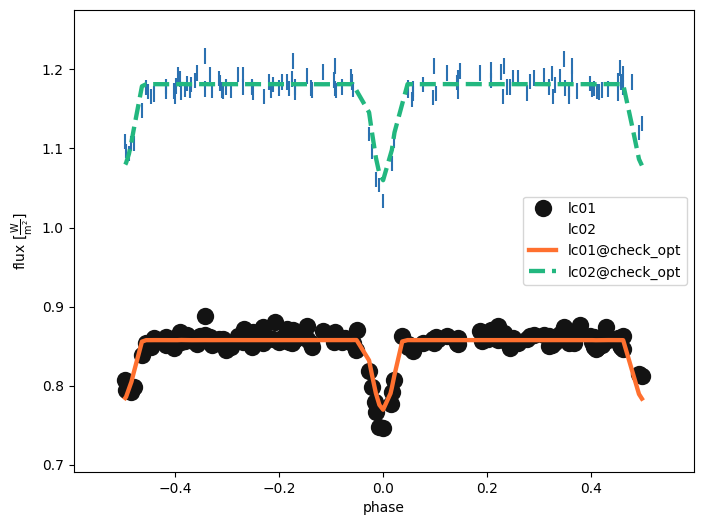

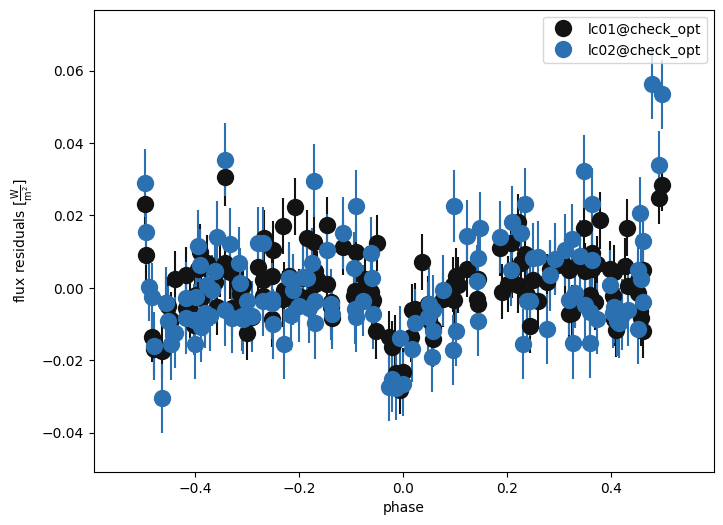

lc01: chi2 = 249.9   chi2_red = 1.70   (N = 147)
lc02: chi2 = 289.5   chi2_red = 2.28   (N = 127)

=== check_final ===


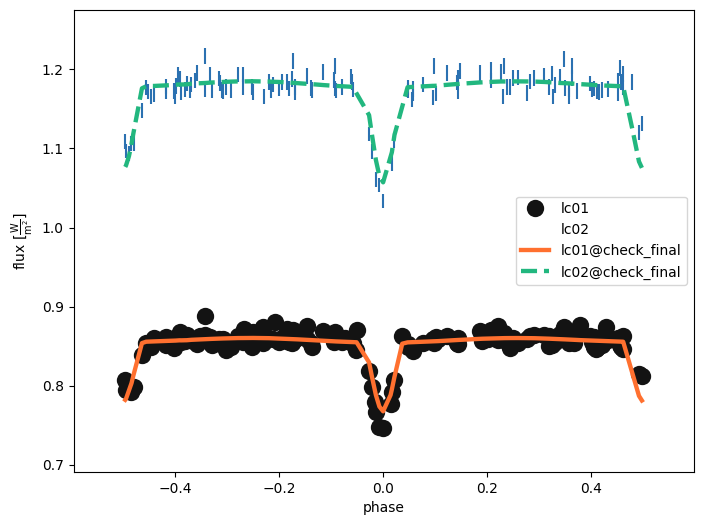

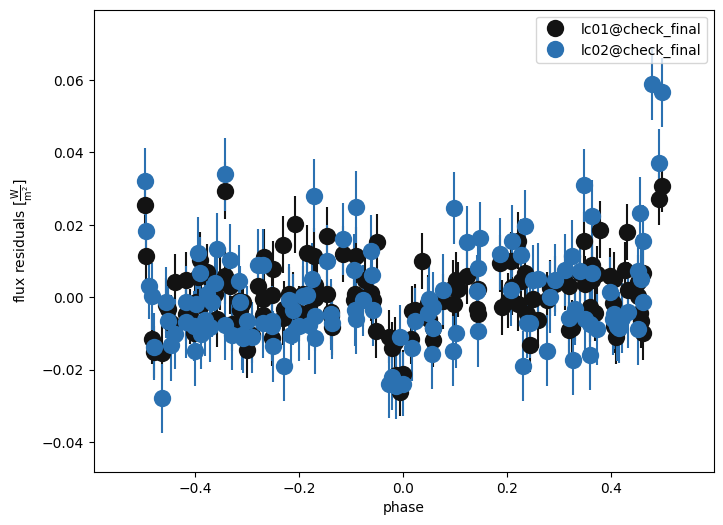

lc01: chi2 = 231.2   chi2_red = 1.57   (N = 147)
lc02: chi2 = 285.4   chi2_red = 2.25   (N = 127)

teffratio = 0.918  ->  con razón < 1 el mínimo de fase 0 debe ser MÁS profundo que el de 0.5
lc01: profundidad fase 0 / fase 0.5 -> datos 0.103 / 0.061  |  modelo 0.078 / 0.084
lc02: profundidad fase 0 / fase 0.5 -> datos 0.104 / 0.061  |  modelo 0.087 / 0.082


100%|██████████| 4/4 [00:00<00:00, 36.93it/s]


Plano del cielo, fase 0.0


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


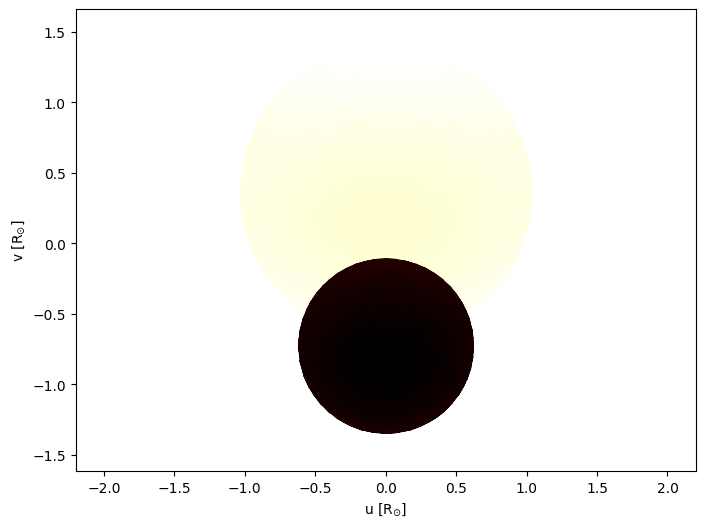

Plano del cielo, fase 0.25


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


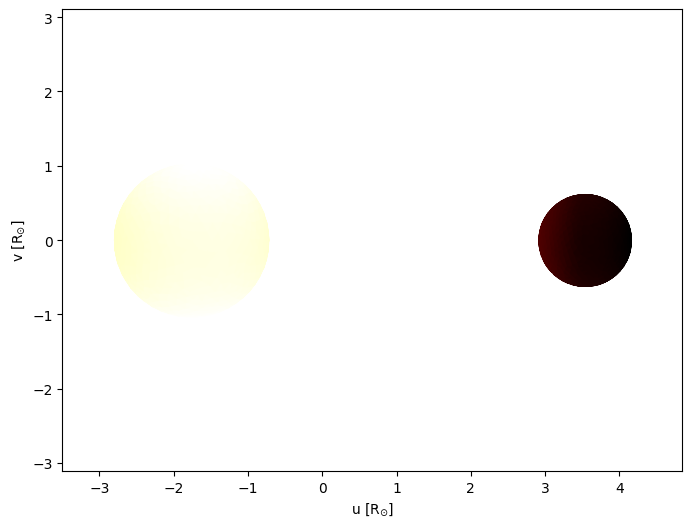

Plano del cielo, fase 0.5


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


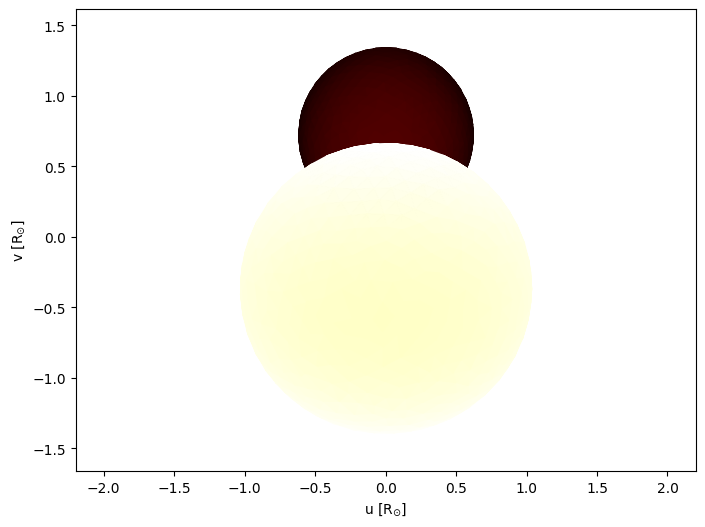

Plano del cielo, fase 0.75


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


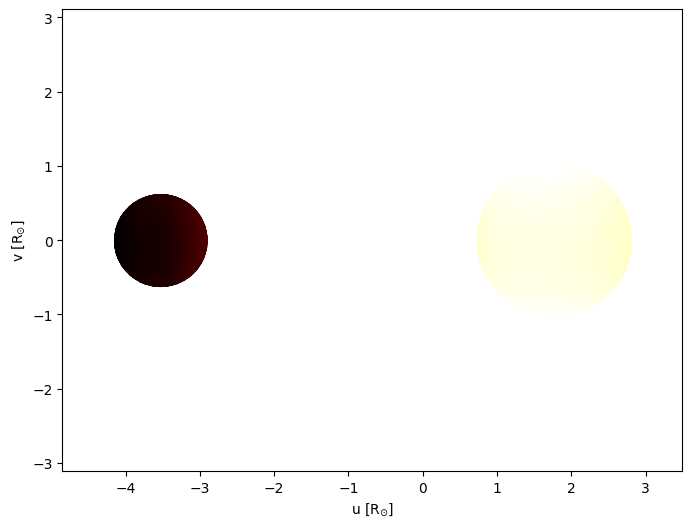

Plano orbital (desde arriba), fase 0.0


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


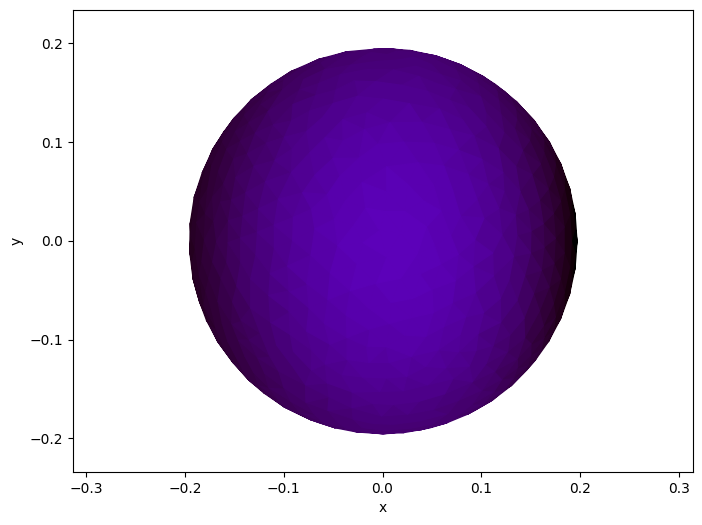

Plano orbital (desde arriba), fase 0.25


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


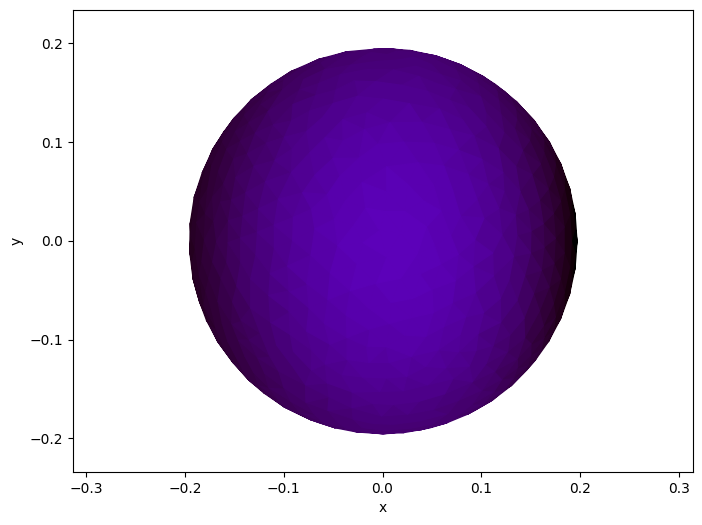

Plano orbital (desde arriba), fase 0.5


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


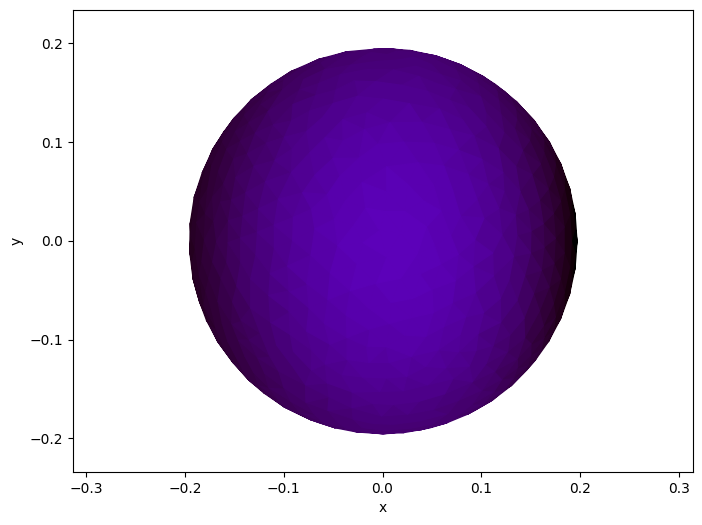

Plano orbital (desde arriba), fase 0.75


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


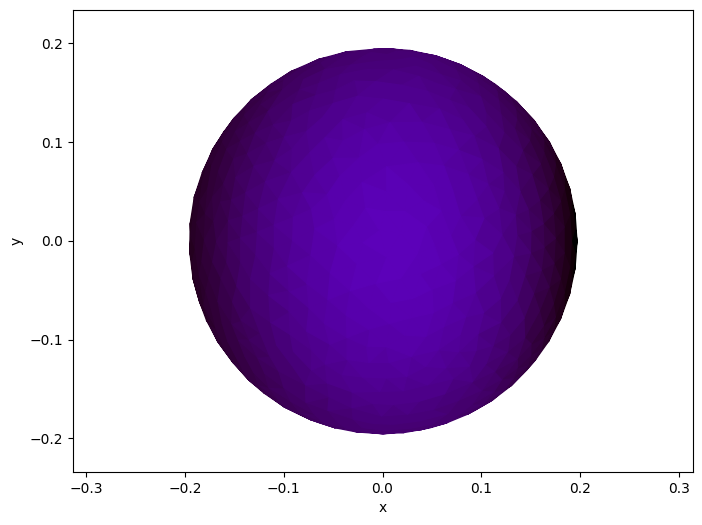

In [2]:
if __name__ == "__main__" and MODE == "fase1":
    b = get_bundle(globals().get("b"))       # en Jupyter reutiliza tu 'b' en memoria
    b = fase1_verificar(b)